# Phase 1: Exploratory Data Analysis

## Goals
- Load and inspect both fraud detection datasets
- Understand class imbalance, feature distributions, and temporal patterns
- Create temporal train/cal/val/test splits
- Establish baseline understanding before modeling

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils.helpers import load_config, set_seed

config = load_config('../configs/config.yaml')
set_seed(config['experiment']['seed'])

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
print('Setup complete.')

Setup complete.


## 1. Load Credit Card Fraud Dataset

In [2]:
# Load Credit Card Fraud dataset
cc_path = f"../{config['data']['creditcard_path']}/creditcard.csv"
df_cc = pd.read_csv(cc_path)
print(f'Shape: {df_cc.shape}')
print(f'\nClass distribution:')
print(df_cc['Class'].value_counts())
print(f'\nFraud rate: {df_cc["Class"].mean():.4f} ({df_cc["Class"].mean()*100:.2f}%)')
df_cc.head()

Shape: (284807, 31)

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Fraud rate: 0.0017 (0.17%)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
# Basic statistics
df_cc.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [4]:
# Missing values
print('Missing values per column:')
missing = df_cc.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else 'No missing values')

Missing values per column:
No missing values


## 2. Class Imbalance Analysis

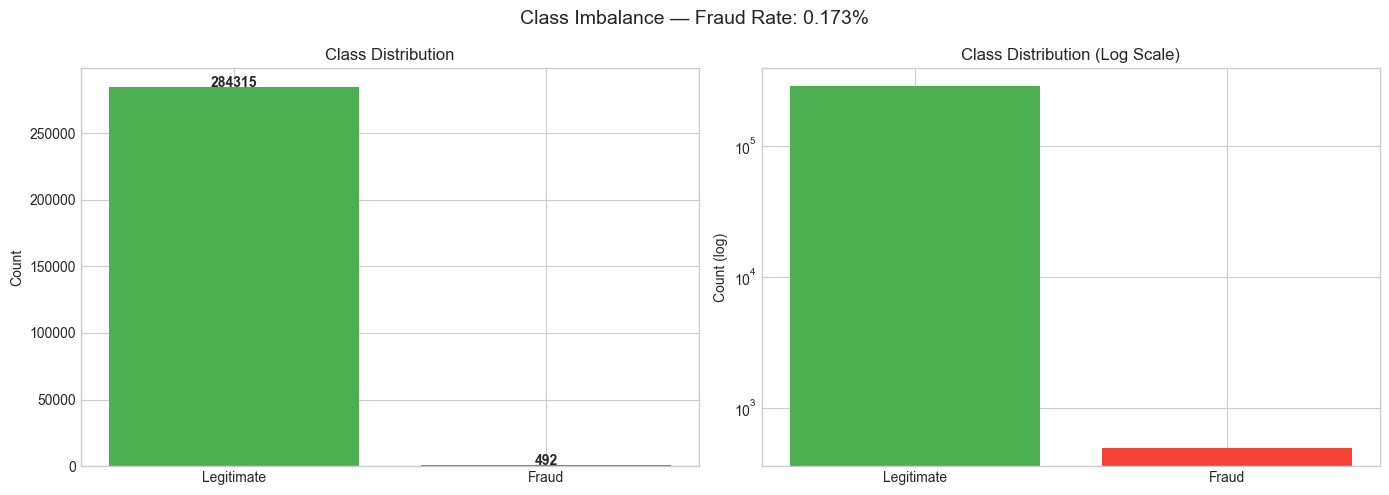

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Class distribution
counts = df_cc['Class'].value_counts()
axes[0].bar(['Legitimate', 'Fraud'], counts.values, color=['#4CAF50', '#F44336'])
axes[0].set_title('Class Distribution')
axes[0].set_ylabel('Count')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 500, str(v), ha='center', fontweight='bold')

# Log scale
axes[1].bar(['Legitimate', 'Fraud'], counts.values, color=['#4CAF50', '#F44336'])
axes[1].set_yscale('log')
axes[1].set_title('Class Distribution (Log Scale)')
axes[1].set_ylabel('Count (log)')

plt.suptitle(f'Class Imbalance — Fraud Rate: {df_cc["Class"].mean()*100:.3f}%', fontsize=14)
plt.tight_layout()
plt.savefig('../results/figures/class_imbalance.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Feature Distributions by Class

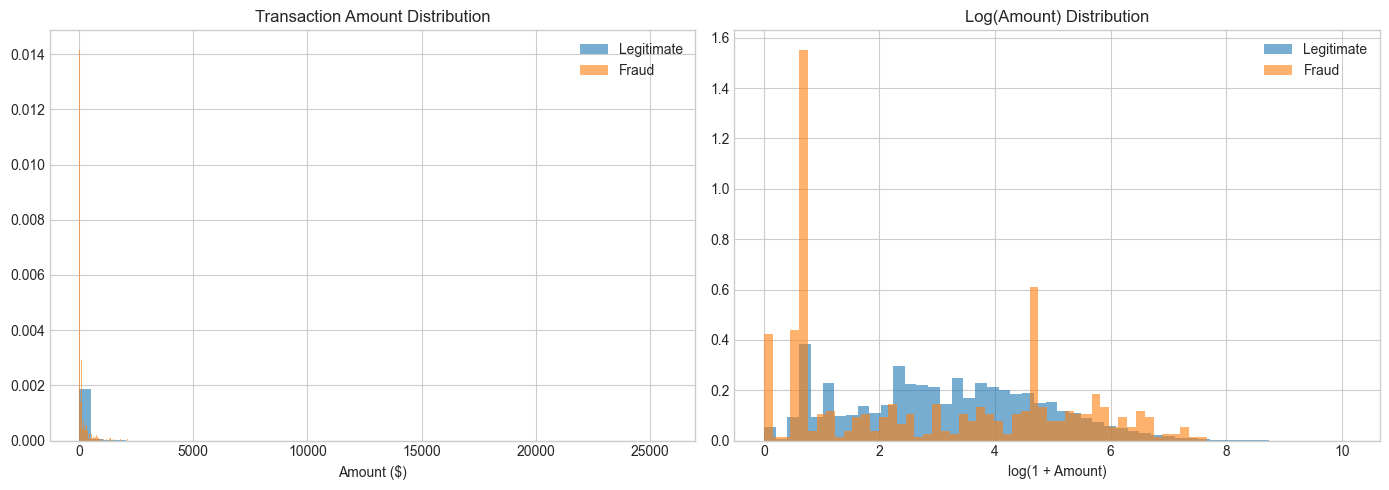

In [6]:
# Amount distribution by class
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, cls_name, cls_val in [(0, 'Legitimate', 0), (1, 'Fraud', 1)]:
    subset = df_cc[df_cc['Class'] == cls_val]
    axes[0].hist(subset['Amount'], bins=50, alpha=0.6, label=cls_name, density=True)
    axes[1].hist(np.log1p(subset['Amount']), bins=50, alpha=0.6, label=cls_name, density=True)

axes[0].set_title('Transaction Amount Distribution')
axes[0].set_xlabel('Amount ($)')
axes[0].legend()

axes[1].set_title('Log(Amount) Distribution')
axes[1].set_xlabel('log(1 + Amount)')
axes[1].legend()

plt.tight_layout()
plt.savefig('../results/figures/amount_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

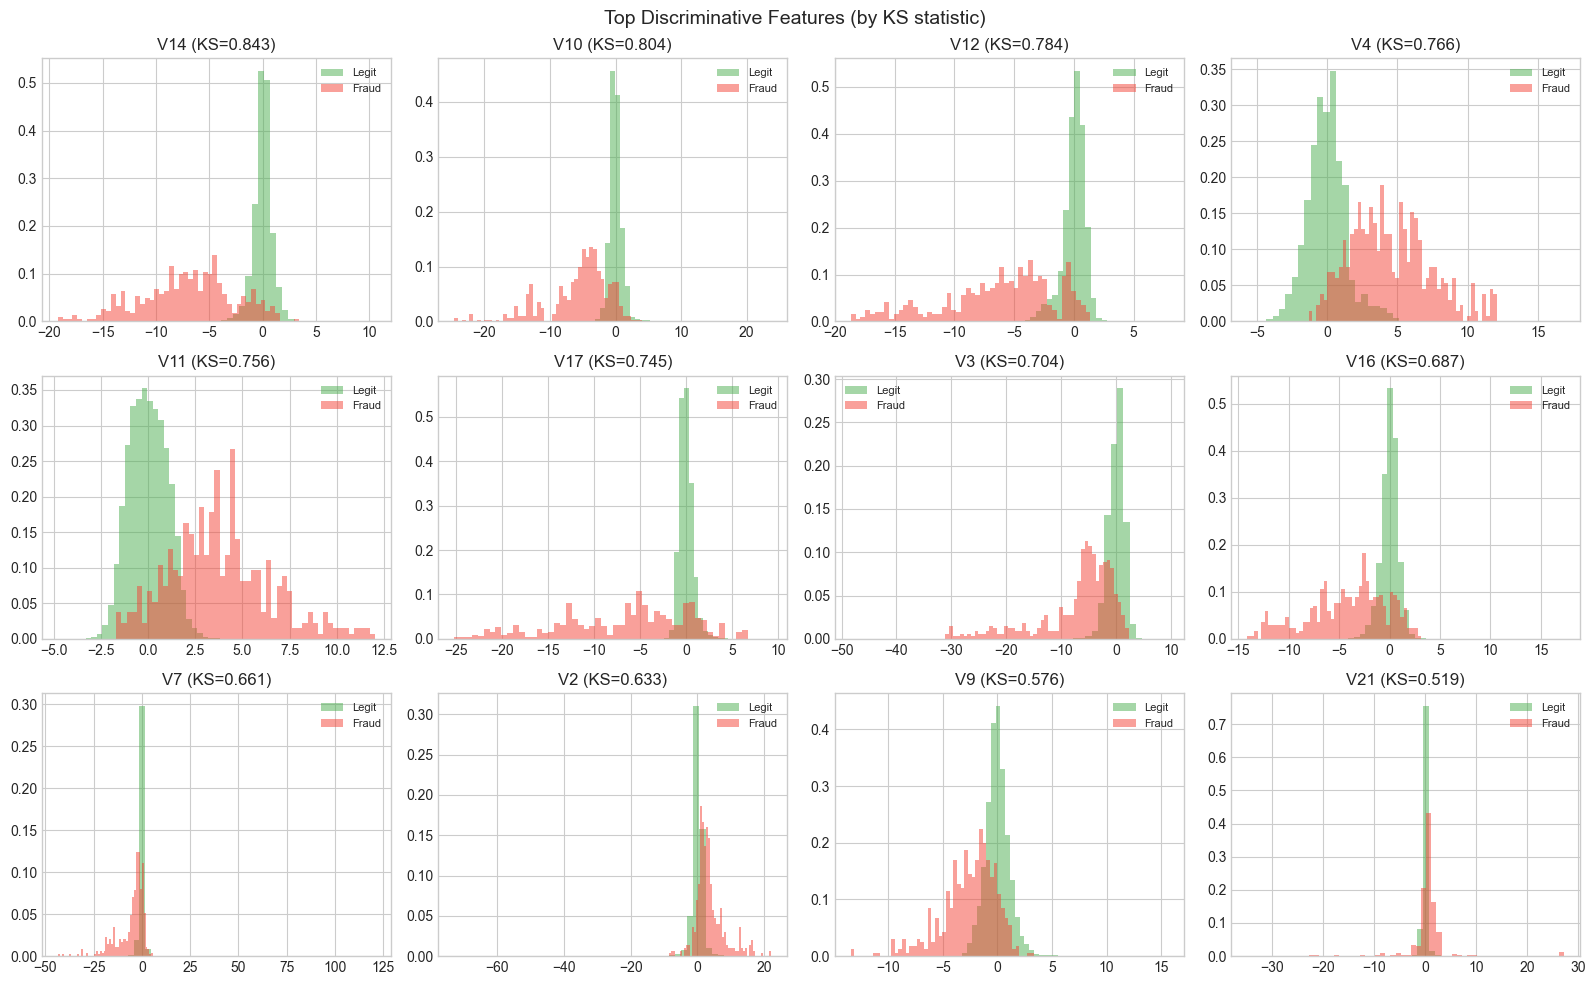

In [7]:
# PCA feature distributions (V1-V28) — show most discriminative
fig, axes = plt.subplots(3, 4, figsize=(16, 10))

# Find features with highest KS statistic between classes
from scipy.stats import ks_2samp
v_cols = [f'V{i}' for i in range(1, 29)]
ks_stats = {}
for col in v_cols:
    stat, _ = ks_2samp(
        df_cc[df_cc['Class']==0][col].dropna(),
        df_cc[df_cc['Class']==1][col].dropna()
    )
    ks_stats[col] = stat

top_features = sorted(ks_stats, key=ks_stats.get, reverse=True)[:12]

for ax, feat in zip(axes.flat, top_features):
    for cls, label, color in [(0, 'Legit', '#4CAF50'), (1, 'Fraud', '#F44336')]:
        ax.hist(df_cc[df_cc['Class']==cls][feat], bins=50, alpha=0.5,
                label=label, density=True, color=color)
    ax.set_title(f'{feat} (KS={ks_stats[feat]:.3f})')
    ax.legend(fontsize=8)

plt.suptitle('Top Discriminative Features (by KS statistic)', fontsize=14)
plt.tight_layout()
plt.savefig('../results/figures/feature_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Temporal Patterns

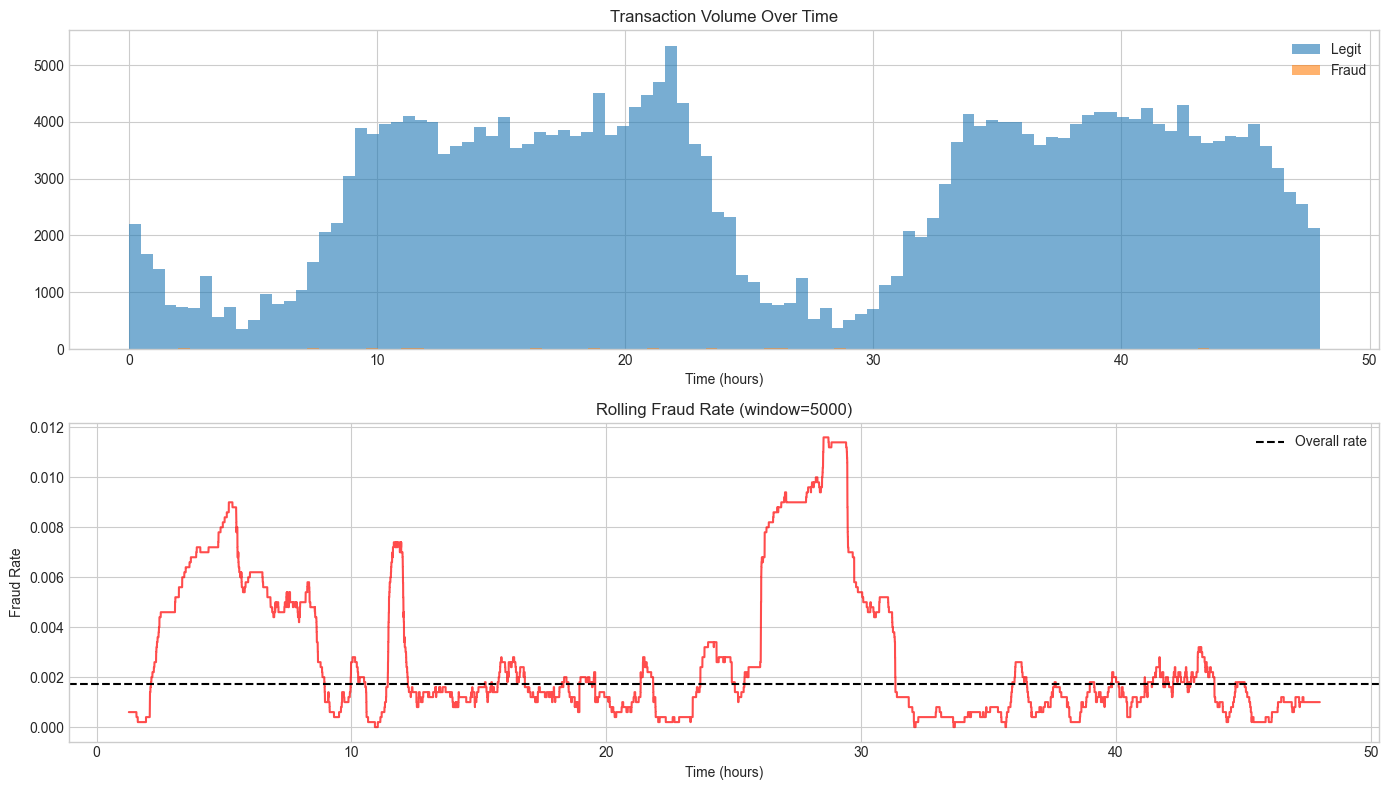

In [8]:
# Time-based fraud rate analysis
df_cc['Time_hours'] = df_cc['Time'] / 3600

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Transaction volume over time
axes[0].hist(df_cc[df_cc['Class']==0]['Time_hours'], bins=100, alpha=0.6, label='Legit')
axes[0].hist(df_cc[df_cc['Class']==1]['Time_hours'], bins=100, alpha=0.6, label='Fraud')
axes[0].set_title('Transaction Volume Over Time')
axes[0].set_xlabel('Time (hours)')
axes[0].legend()

# Rolling fraud rate
df_sorted = df_cc.sort_values('Time')
window = 5000
rolling_fraud_rate = df_sorted['Class'].rolling(window).mean()
axes[1].plot(df_sorted['Time_hours'].values, rolling_fraud_rate.values, color='red', alpha=0.7)
axes[1].set_title(f'Rolling Fraud Rate (window={window})')
axes[1].set_xlabel('Time (hours)')
axes[1].set_ylabel('Fraud Rate')
axes[1].axhline(y=df_cc['Class'].mean(), color='black', linestyle='--', label='Overall rate')
axes[1].legend()

plt.tight_layout()
plt.savefig('../results/figures/temporal_patterns.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Create Temporal Splits

In [9]:
from src.data.splits import temporal_split_creditcard

splits = temporal_split_creditcard(df_cc)

print('Temporal Split Summary:')
print('=' * 50)
for name, idx in splits.items():
    y_split = df_cc.iloc[idx]['Class'].values
    time_range = df_cc.iloc[idx]['Time_hours']
    print(f'{name:15s}: n={len(idx):6d}, fraud_rate={y_split.mean():.4f}, '
          f'time=[{time_range.min():.1f}h - {time_range.max():.1f}h]')

Temporal Split Summary:
train          : n=170884, fraud_rate=0.0021, time=[0.0h - 33.4h]
calibration    : n= 42721, fraud_rate=0.0009, time=[33.4h - 38.7h]
val            : n= 28480, fraud_rate=0.0015, time=[38.7h - 42.0h]
test           : n= 42722, fraud_rate=0.0012, time=[42.0h - 48.0h]


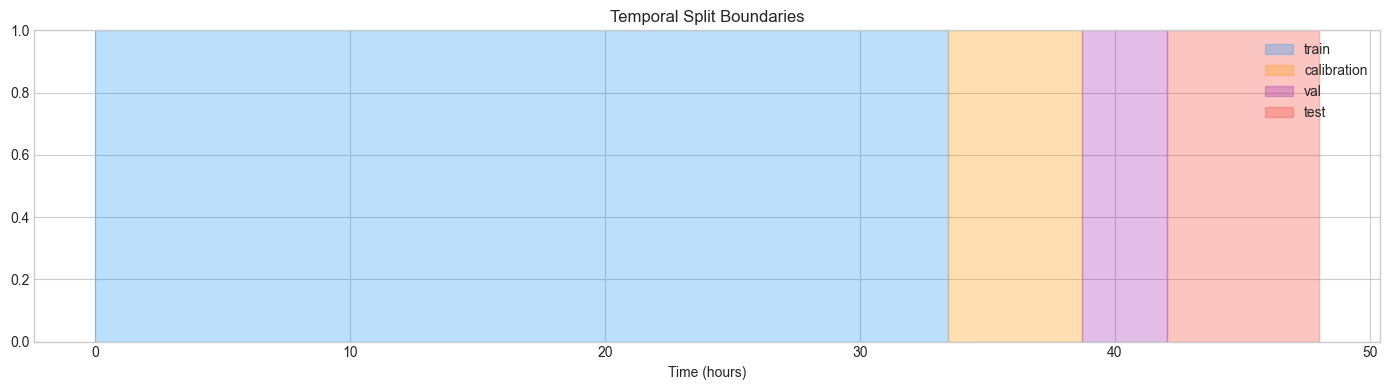

In [10]:
# Visualize temporal splits
fig, ax = plt.subplots(figsize=(14, 4))

colors = {'train': '#2196F3', 'calibration': '#FF9800', 'val': '#9C27B0', 'test': '#F44336'}

for name, idx in splits.items():
    times = df_cc.iloc[idx]['Time_hours'].values
    ax.axvspan(times.min(), times.max(), alpha=0.3, color=colors[name], label=name)

ax.set_xlabel('Time (hours)')
ax.set_title('Temporal Split Boundaries')
ax.legend()
plt.tight_layout()
plt.savefig('../results/figures/temporal_splits.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Feature Correlations

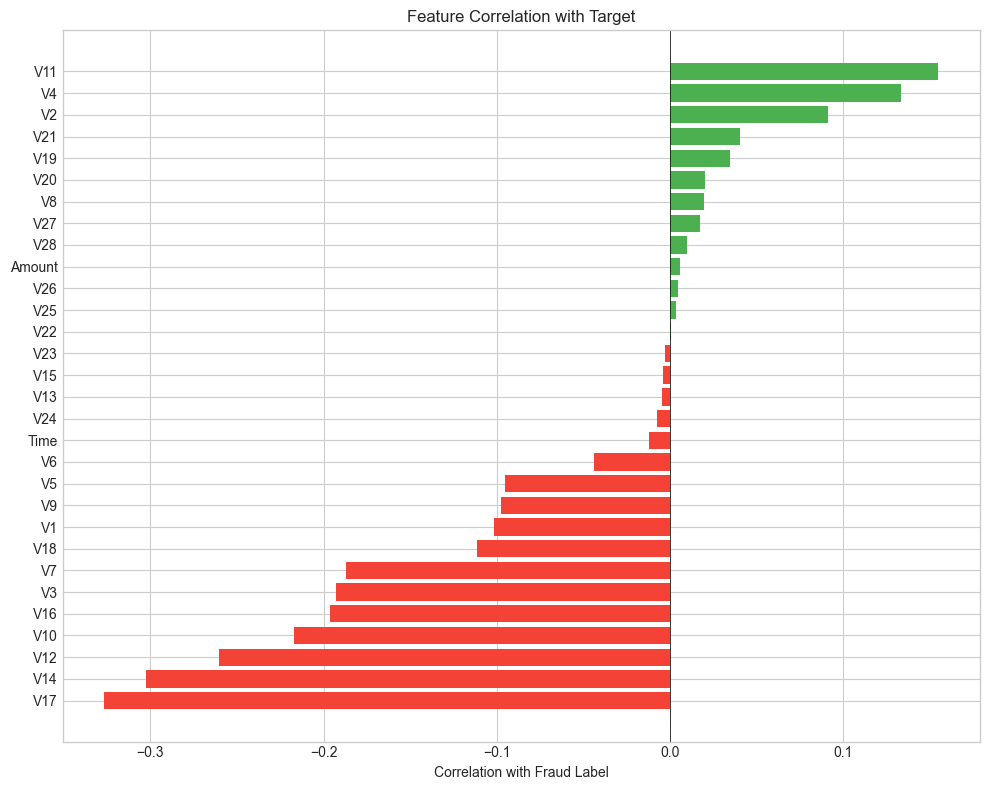

In [11]:
# Correlation with target
correlations = df_cc.drop(columns=['Time_hours']).corr()['Class'].drop('Class').sort_values()

fig, ax = plt.subplots(figsize=(10, 8))
colors = ['#F44336' if v < 0 else '#4CAF50' for v in correlations.values]
ax.barh(correlations.index, correlations.values, color=colors)
ax.set_xlabel('Correlation with Fraud Label')
ax.set_title('Feature Correlation with Target')
ax.axvline(x=0, color='black', linewidth=0.5)
plt.tight_layout()
plt.savefig('../results/figures/feature_correlations.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Key Observations for Research

Document your findings here:

1. **Class Imbalance**: Fraud rate is ~0.17%, creating extreme imbalance
2. **Temporal Patterns**: Does fraud rate change over time? (key for shift experiments)
3. **Feature Separability**: Which features best distinguish fraud from legit?
4. **Implications for Calibration**: High imbalance means most bins in reliability diagram will be near 0